# Projeto 2: descontando a inflação com o `python-bcb`

**Ciência dos Dados · Insper · 2026.2**

No Projeto 2 vocês comparam o VM2 (R\$ por m²) de 2019 com o de 2025. Entre esses anos
houve inflação: um real de 2019 comprava mais do que um real de 2025. Para saber se o
metro quadrado ficou mais caro **de verdade**, é preciso colocar os dois anos na mesma
moeda, por exemplo em **reais de 2025**.

Este notebook mostra como fazer isso com o **IPCA**, o índice oficial de inflação do
Brasil, baixado direto do Banco Central com o pacote
[`python-bcb`](https://wilsonfreitas.github.io/python-bcb/).

Roteiro:

1. baixar o IPCA mensal (série 433 do SGS, o Sistema Gerenciador de Séries Temporais do BC);
2. transformar as variações mensais em um **número-índice**;
3. calcular o **fator de correção** de 2019 para 2025;
4. aplicar o fator ao VM2.

## 0. Instalação

No Colab (ou se o pacote ainda não estiver instalado), rode a célula abaixo uma vez.

In [1]:
%pip install -q python-bcb

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bcb import sgs

## 1. Baixando o IPCA

A série **433** do SGS é a variação **mensal** do IPCA, em %. O `sgs.get` recebe um
dicionário `{nome da coluna: código da série}` e o período, e devolve um DataFrame
indexado pela data.

In [3]:
ipca = sgs.get({'ipca': 433}, start='2019-01-01', end='2025-12-31')
ipca.head()

,ipca
Date,
2019-01-01,0.32
2019-02-01,0.43
2019-03-01,0.75
2019-04-01,0.57
2019-05-01,0.13


Cada linha diz quanto os preços subiram **naquele mês**. Por exemplo, 0,32 em
janeiro de 2019 quer dizer que os preços subiram 0,32% de dezembro de 2018 para
janeiro de 2019.

## 2. Das variações mensais ao número-índice

Variações mensais não se somam, elas se **multiplicam**: se os preços sobem 1% em um
mês e 1% no outro, o acumulado é $1{,}01 \times 1{,}01 = 1{,}0201$, ou seja, 2,01%.

Por isso transformamos cada variação em um fator $1 + \frac{\text{ipca}}{100}$ e
fazemos o produto acumulado (`cumprod`). O resultado é um **número-índice**: o nível
de preços de cada mês, com base 100 em dezembro de 2018.

In [4]:
ipca['indice'] = 100 * (1 + ipca['ipca'] / 100).cumprod()
ipca['ano'] = ipca.index.year
ipca.tail()

,ipca,indice,ano
Date,,,
2025-08-01,-0.11,143.588298,2025
2025-09-01,0.48,144.277522,2025
2025-10-01,0.09,144.407372,2025
2025-11-01,0.18,144.667305,2025
2025-12-01,0.33,145.144707,2025


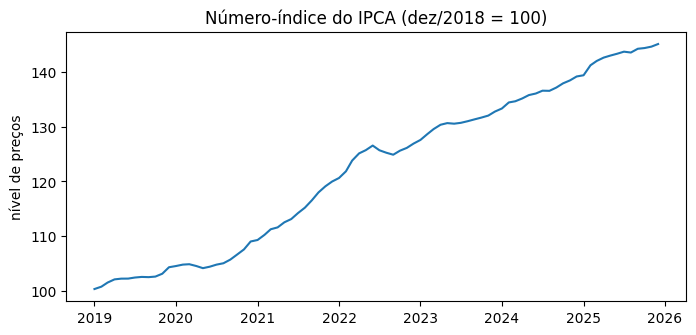

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ipca.index, ipca['indice'])
ax.set_title('Número-índice do IPCA (dez/2018 = 100)')
ax.set_ylabel('nível de preços')
plt.show()

## 3. O fator de correção de 2019 para 2025

As vendas do ITBI estão espalhadas pelos 12 meses de cada ano. Por isso comparamos o
**nível médio de preços** de cada ano: a média do índice em 2025 dividida pela média
do índice em 2019.

In [6]:
media_anual = ipca.groupby('ano')['indice'].mean()
fator = media_anual[2025] / media_anual[2019]
print(f'Fator de correção 2019 -> 2025: {fator:.4f}')
print(f'Inflação entre os dois anos: {100 * (fator - 1):.1f}%')

Fator de correção 2019 -> 2025: 1.4003
Inflação entre os dois anos: 40.0%


Os preços, em média, ficaram cerca de **40% mais altos** em 2025 do que em 2019.
Então R\$ 1,00 de 2019 equivale a cerca de R\$ 1,40 de 2025.

> **Outra escolha possível:** comparar dezembro com dezembro (ou o mês de cada
> transação, como na seção 5). O fator muda um pouco. O importante é **dizer no
> relatório qual escolha vocês fizeram** e por quê.

In [7]:
fator_dez = ipca.loc['2025-12-01', 'indice'] / ipca.loc['2019-12-01', 'indice']
print(f'Fator dez/2019 -> dez/2025: {fator_dez:.4f}')

Fator dez/2019 -> dez/2025: 1.3915


## 4. Aplicando ao VM2

Para levar um valor de 2019 a **reais de 2025**, basta multiplicar pelo fator. Os
valores de 2025 ficam como estão.

Um exemplo com números redondos: suponha que a mediana do VM2 tenha passado de
R\$ 4.400 em 2019 para R\$ 5.900 em 2025.

In [8]:
vm2_2019, vm2_2025 = 4400, 5900

variacao_nominal = vm2_2025 / vm2_2019 - 1
vm2_2019_em_reais_de_2025 = vm2_2019 * fator
variacao_real = vm2_2025 / vm2_2019_em_reais_de_2025 - 1

print(f'2019 em reais de 2025: R$ {vm2_2019_em_reais_de_2025:.0f}')
print(f'Variação nominal: {100 * variacao_nominal:+.1f}%')
print(f'Variação real:    {100 * variacao_real:+.1f}%')

2019 em reais de 2025: R$ 6161
Variação nominal: +34.1%
Variação real:    -4.2%


Em reais da época, o metro quadrado subiu cerca de 34%. Descontada a inflação, ele
ficou um pouco **mais barato**. É essa a diferença entre a variação **nominal** e a
variação **real**.

### Na base do projeto

Com a base de vocês num DataFrame (aqui chamado `dados`, com a coluna `vm2` e a data
da transação em `data_transacao`), a correção é uma linha:

In [9]:
# exemplo pequeno, só para mostrar o formato; usem a base de vocês
dados = pd.DataFrame({
    'data_transacao': pd.to_datetime(['2019-03-15', '2019-11-02', '2025-05-20', '2025-08-09']),
    'vm2': [4200.0, 4600.0, 5800.0, 6100.0],
})

dados['ano'] = dados['data_transacao'].dt.year
dados['vm2_real'] = np.where(dados['ano'] == 2019, dados['vm2'] * fator, dados['vm2'])
dados

,data_transacao,vm2,ano,vm2_real
0,2019-03-15,4200.0,2019,5881.408115
1,2019-11-02,4600.0,2019,6441.542221
2,2025-05-20,5800.0,2025,5800.000000
3,2025-08-09,6100.0,2025,6100.000000


A partir daí, as comparações entre 2019 e 2025 (médias, medianas, histogramas,
boxplots) podem ser feitas com `vm2` (nominal) e com `vm2_real` (em reais de 2025).

## 5. Opcional: corrigindo mês a mês

Uma venda de janeiro de 2019 e uma de dezembro de 2019 enfrentaram níveis de preço
diferentes. Para ser mais preciso, dá para corrigir cada transação pelo índice do
**mês em que ela aconteceu**, sempre levando para a média de 2025.

In [10]:
indice_mes = ipca['indice'].rename('indice_mes')
dados['mes'] = dados['data_transacao'].dt.to_period('M').dt.to_timestamp()
dados = dados.merge(indice_mes, left_on='mes', right_index=True, how='left')
dados['vm2_real_mes'] = dados['vm2'] * media_anual[2025] / dados['indice_mes']
dados

,data_transacao,vm2,ano,vm2_real,mes,indice_mes,vm2_real_mes
0,2019-03-15,4200.0,2019,5881.408115,2019-03-01,101.507011,5922.461340
1,2019-11-02,4600.0,2019,6441.542221,2019-11-01,103.120158,6385.034471
2,2025-05-20,5800.0,2025,5800.000000,2025-05-01,143.030375,5804.284631
3,2025-08-09,6100.0,2025,6100.000000,2025-08-01,143.588298,6080.786724


## Referências

- Banco Central do Brasil. *Sistema Gerenciador de Séries Temporais (SGS)*, série 433:
  IPCA, variação mensal (%). <https://www3.bcb.gov.br/sgspub>
- Freitas, W. *python-bcb*. <https://wilsonfreitas.github.io/python-bcb/>